# Session 6 — Artificial Neural Networks

#### 0. Setup

In [6]:
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score

In [7]:
import sys
import time
import json
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score


def find_project_root():
    """Walk up from the notebook's folder until data/milk10k/metadata.csv is found."""
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "milk10k" / "metadata.csv").is_file():
            return p
    raise FileNotFoundError(f"data/milk10k/metadata.csv not found above {start}")


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))          # lets you still do `from src.data import ...` if you want

np.set_printoptions(precision=3, suppress=True)
random.seed(0); np.random.seed(0); torch.manual_seed(0)

print("project root:", ROOT)
print("torch", torch.__version__)

project root: /Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification
torch 2.14.0


### 1. One neuron, by hand → in NumPy

In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def neuron(x, w, b):
    z = np.dot(x, w) + b          # 1. weighted sum
    return z, sigmoid(z)          # 2. activation

x = np.array([0.6, 0.2])          # edge density, color asymmetry (normalized)
w = np.array([1.5, -0.5])
b = -0.4
neuron(x, w, b)                   # (0.4, 0.599)

(np.float64(0.3999999999999999), np.float64(0.598687660112452))

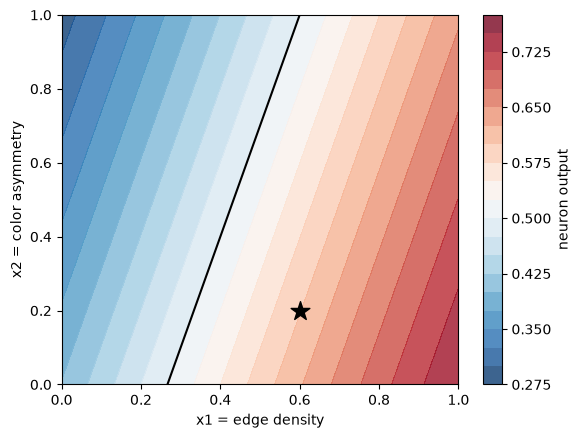

In [9]:
g1, g2 = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
_, p = neuron(np.stack([g1, g2], axis=-1), w, b)       # works on the whole grid at once

plt.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.8)
plt.colorbar(label="neuron output")
plt.contour(g1, g2, p, levels=[0.5], colors="k")       # the decision boundary: z = 0
plt.scatter(*x, c="k", marker="*", s=200)              # our lesion: 0.599
plt.xlabel("x1 = edge density"); plt.ylabel("x2 = color asymmetry");

### 2. XOR — what one line cannot do

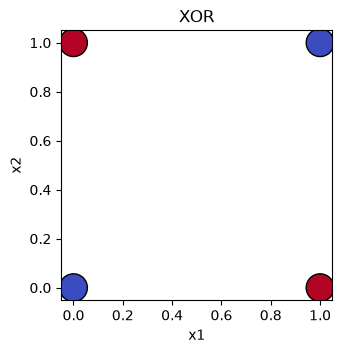

In [10]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

plt.figure(figsize=(3.5, 3.5))
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("XOR");

In [11]:
def relu(z):
    return np.maximum(0, z)

W1 = np.array([[1, 1],
               [1, 1]], dtype=float)     # column j = weights of hidden neuron j
b1 = np.array([0, -1], dtype=float)
W2 = np.array([1, -2], dtype=float)

H = relu(X_xor @ W1 + b1)                # hidden layer: 4 inputs x 2 neurons
out = H @ W2
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1],
              "h1": H[:, 0], "h2": H[:, 1], "output": out, "XOR": y_xor})

,x1,x2,h1,h2,output,XOR
0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,1.0,1.0,0.0,1.0,1
2,1.0,0.0,1.0,0.0,1.0,1
3,1.0,1.0,2.0,1.0,0.0,0


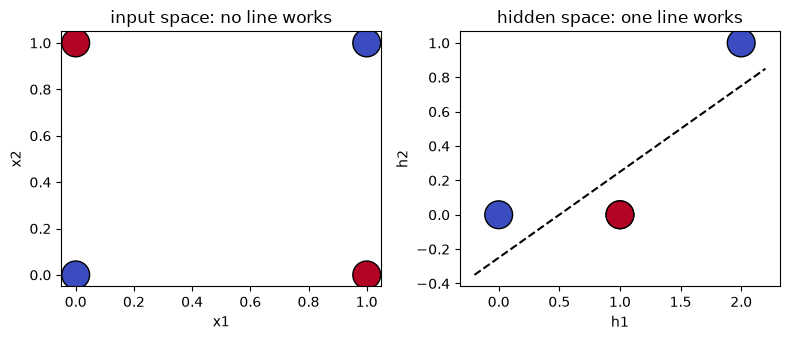

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
axes[0].set_title("input space: no line works"); axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[1].scatter(H[:, 0], H[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
h1_line = np.linspace(-0.2, 2.2, 10)
axes[1].plot(h1_line, (h1_line - 0.5) / 2, "k--")       # output = h1 - 2*h2 = 0.5
axes[1].set_title("hidden space: one line works"); axes[1].set_xlabel("h1"); axes[1].set_ylabel("h2")
plt.tight_layout()

In [13]:
linear_out = (X_xor @ W1 + b1) @ W2               # same network, NO ReLU
collapsed = X_xor @ (W1 @ W2) + (b1 @ W2)          # one equivalent linear layer
print(linear_out, collapsed)                       # [2. 1. 1. 0.] twice -> not XOR
print(W1 @ W2, b1 @ W2)                            # [-1. -1.] 2.0

[2. 1. 1. 0.] [2. 1. 1. 0.]
[-1. -1.] 2.0


### 3. Forward pass, softmax, cross-entropy

In [14]:
def forward(x, W1, b1, W2, b2):
    z_h = x @ W1 + b1          # hidden pre-activations
    h = relu(z_h)              # hidden activations
    z_o = h @ W2 + b2          # output pre-activation
    return sigmoid(z_o), h, z_h

W1 = np.array([[0.5, -0.3],
               [0.3,  0.4]]); b1 = np.array([0.1, -0.3])
W2 = np.array([0.4, -0.2]);   b2 = 0.1

y_hat, h, z_h = forward(np.array([0.6, 0.2]), W1, b1, W2, b2)
print(z_h, h, y_hat)           # [ 0.46 -0.4 ] [0.46 0.  ] 0.570

[ 0.46 -0.4 ] [0.46 0.  ] 0.5705266031962988


In [15]:
def softmax(z):
    e = np.exp(z - z.max())    # subtract max: same result, no overflow
    return e / e.sum()

logits = np.array([1.0, 2.0, 0.5])          # Benign, Malignant, Indeterminate
print(np.exp(logits))                       # [2.718 7.389 1.649]
print(softmax(logits))                      # [0.231 0.629 0.14 ]

[2.718 7.389 1.649]
[0.231 0.629 0.14 ]


In [16]:
def cross_entropy(y_true_onehot, probs, eps=1e-9):
    probs = np.clip(probs, eps, 1 - eps)                 # avoid log(0)
    return -np.sum(y_true_onehot * np.log(probs))

y_true = np.array([0, 1, 0])                             # truth: Malignant
for probs in ([0.10, 0.70, 0.20], [0.005, 0.99, 0.005], [0.80, 0.10, 0.10]):
    print(probs, "->", round(cross_entropy(y_true, np.array(probs)), 3))   # 0.357 / 0.01 / 2.303

[0.1, 0.7, 0.2] -> 0.357
[0.005, 0.99, 0.005] -> 0.01
[0.8, 0.1, 0.1] -> 2.303


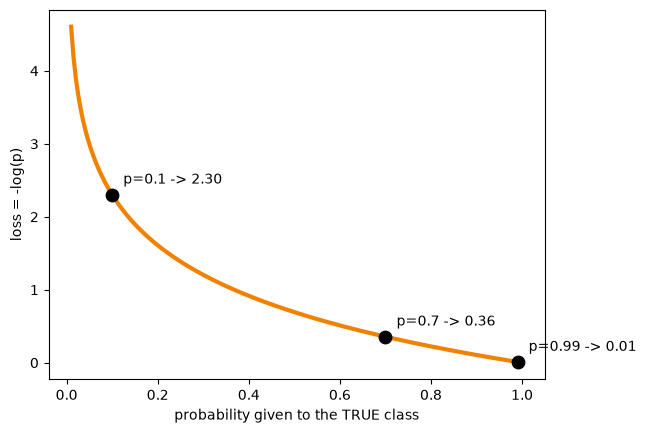

In [17]:
p = np.linspace(0.01, 1, 200)
plt.plot(p, -np.log(p), color="#F08200", lw=3)
for q in (0.10, 0.70, 0.99):
    plt.scatter(q, -np.log(q), s=80, color="k", zorder=3)
    plt.annotate(f"p={q} -> {-np.log(q):.2f}", (q, -np.log(q)), xytext=(8, 8), textcoords="offset points")
plt.xlabel("probability given to the TRUE class"); plt.ylabel("loss = -log(p)");

### 4. Gradient descent by hand

In [18]:
def descend(lr, w=0.0, steps=15):
    path = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)       # slope of (w - 3)**2
        w = w - lr * grad        # one step downhill
        path.append(w)
    return np.array(path)

path = descend(lr=0.1)
print(path[:4])                  # [0.    0.6   1.08  1.464]
print(path[-1])                  # 2.894 after 15 steps -> close to 3

[0.    0.6   1.08  1.464]
2.894446883733504


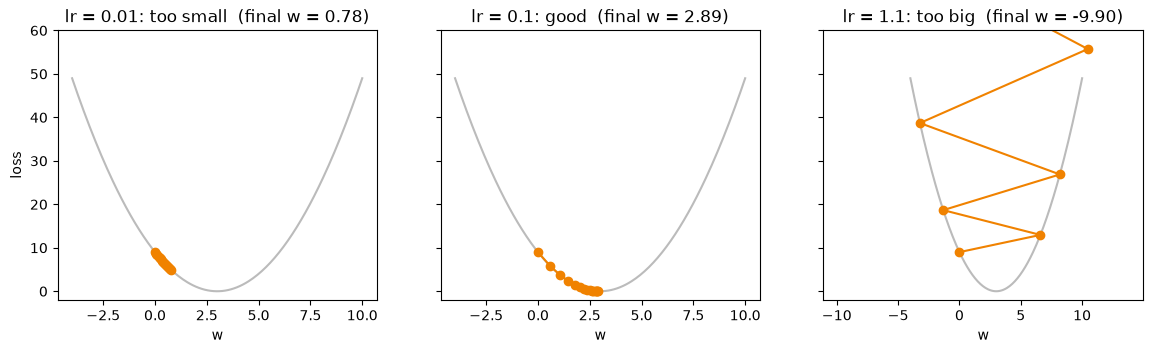

In [19]:
ws = np.linspace(-4, 10, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, lr, title in zip(axes, [0.01, 0.1, 1.1], ["too small", "good", "too big"]):
    path = descend(lr, steps=8 if lr > 1 else 15)
    ax.plot(ws, (ws - 3) ** 2, color="#BBBBBB")
    ax.plot(path, (path - 3) ** 2, "o-", color="#F08200")
    ax.set_title(f"lr = {lr}: {title}  (final w = {path[-1]:.2f})")
    ax.set_ylim(-2, 60); ax.set_xlabel("w")
axes[0].set_ylabel("loss");

### 5. Backpropagation by hand — then let PyTorch check us

In [20]:
y = 1.0                                       # truth: malignant
z, y_hat = neuron(x, w, b)
loss = -np.log(y_hat)
print(f"forward : z={z:.3f}  y_hat={y_hat:.3f}  loss={loss:.3f}")      # 0.4  0.599  0.513

dz = y_hat - y                                # dLoss/dz for sigmoid + cross-entropy
grad_w = dz * x                               # chain rule: dLoss/dw = dLoss/dz * dz/dw = dz * x
grad_b = dz * 1
print(f"backward: dz={dz:.3f}  grad_w={grad_w}  grad_b={grad_b:.3f}")  # -0.401  [-0.241 -0.08 ]  -0.401

forward : z=0.400  y_hat=0.599  loss=0.513
backward: dz=-0.401  grad_w=[-0.241 -0.08 ]  grad_b=-0.401


In [21]:
lr = 1.0
w_new = w - lr * grad_w
b_new = b - lr * grad_b
z2, y_hat2 = neuron(x, w_new, b_new)
print(w_new, round(b_new, 3))                                  # [ 1.741 -0.42 ]  0.001
print(f"y_hat {y_hat:.3f} -> {y_hat2:.3f}   loss {loss:.3f} -> {-np.log(y_hat2):.3f}")   # 0.599 -> 0.723   0.513 -> 0.324

[ 1.741 -0.42 ] 0.001
y_hat 0.599 -> 0.723   loss 0.513 -> 0.324


In [22]:
import torch
import torch.nn as nn

xt = torch.tensor([0.6, 0.2])
wt = torch.tensor([1.5, -0.5], requires_grad=True)   # track gradients for these
bt = torch.tensor(-0.4, requires_grad=True)

y_hat_t = torch.sigmoid(xt @ wt + bt)                # forward, same formula
loss_t = -torch.log(y_hat_t)
loss_t.backward()                                    # backpropagation, automatic

print(y_hat_t.item(), loss_t.item())                 # 0.599  0.513
print(wt.grad, bt.grad)                              # tensor([-0.2408, -0.0803])  tensor(-0.4013)

0.5986876487731934 0.5130152702331543
tensor([-0.2408, -0.0803]) tensor(-0.4013)


### 6. A real (tiny) network learns a curved boundary

In [23]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
Xm_t = torch.tensor(Xm, dtype=torch.float32)
ym_t = torch.tensor(ym)

def make_net(hidden):
    torch.manual_seed(0)
    if hidden == 0:
        return nn.Linear(2, 2)                            # no hidden layer = logistic regression
    return nn.Sequential(nn.Linear(2, hidden), nn.ReLU(), nn.Linear(hidden, 2))

net = make_net(8)
net

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=2, bias=True)
)

In [24]:
def train(net, X, y, epochs=1000, lr=0.01):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        optimizer.zero_grad()            # 1. forget old gradients
        loss = loss_fn(net(X), y)        # 2. forward + loss
        loss.backward()                  # 3. backprop
        optimizer.step()                 # 4. w <- w - lr * grad  (Adam's version)
    return loss.item()

def plot_boundary(net, ax, title):
    g1, g2 = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = torch.tensor(np.c_[g1.ravel(), g2.ravel()], dtype=torch.float32)
    with torch.no_grad():
        p = torch.softmax(net(grid), dim=1)[:, 1].reshape(g1.shape)
    ax.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.7)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

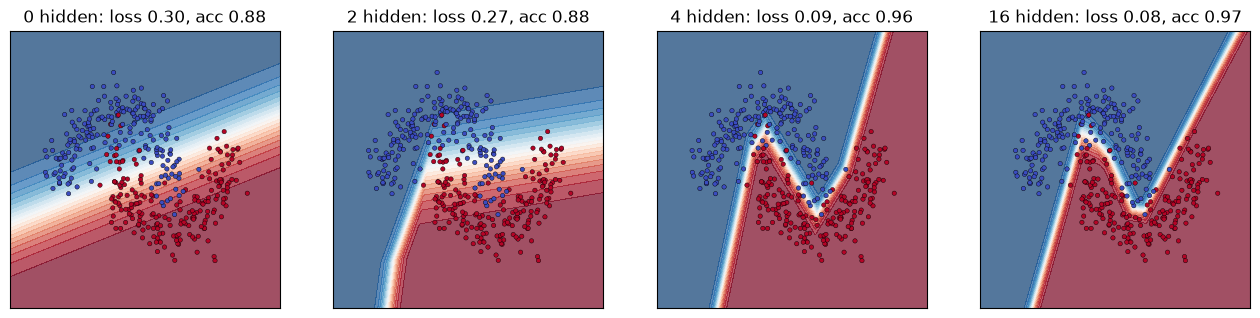

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, hidden in zip(axes, [0, 2, 4, 16]):
    net = make_net(hidden)
    final_loss = train(net, Xm_t, ym_t)
    with torch.no_grad():
        acc = (net(Xm_t).argmax(1) == ym_t).float().mean().item()
    plot_boundary(net, ax, f"{hidden} hidden: loss {final_loss:.2f}, acc {acc:.2f}")
# acc: 0 hidden 0.88 (a line) · 2 hidden 0.88 · 4 hidden 0.96 · 16 hidden 0.97

### 7. Back to MILK10k — Session 5's 33 features

In [26]:
import sys
from pathlib import Path

# Add project root directory to sys.path
parent_dir = Path().resolve().parent
if str(parent_dir) not in sys.path:
    sys.path.append(str(parent_dir))

# Import from src.data.loaders (or src.data.dataset depending on where load_metadata is defined)
from src.data import loaders as milk10k

print("Successfully imported milk10k!")

Successfully imported milk10k!


In [27]:
import sys
from pathlib import Path

# 1. Add the project root directory to sys.path
parent_dir = Path().resolve().parent
if str(parent_dir) not in sys.path:
    sys.path.append(str(parent_dir))

# 2. Import dataset.py as milk10k
from src.data import dataset as milk10k

print("Successfully imported milk10k from dataset.py!")

Successfully imported milk10k from dataset.py!


In [28]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
from sklearn.model_selection import StratifiedGroupKFold


# ---- Project paths (no hard-coded /Users/... path) ---------------------------------
def find_project_root():
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "milk10k" / "metadata.csv").is_file():
            return p
    raise FileNotFoundError("data/milk10k/metadata.csv not found above " + str(start))

ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "milk10k"
IMG_DIR = DATA_DIR / "images"

# isic_id -> file path (works with flat or nested image folders)
image_index = {p.stem: p for p in IMG_DIR.rglob("*")
               if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
print("images indexed:", len(image_index))


# ---- Session 5 ---------------------------------------------------------------------
def color_stats(rgb):
    return np.concatenate([rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1))])

def color_histogram(rgb, bins=8):
    n_pixels = rgb.shape[0] * rgb.shape[1]
    return np.concatenate([np.histogram(rgb[:, :, c], bins=bins, range=(0, 256))[0] / n_pixels
                           for c in range(3)])

def texture_features(rgb):
    gray = rgb.mean(axis=2)
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray**2, size=9)
    return np.array([np.hypot(gx, gy).mean(),
                     (local_sq_mean - local_mean**2).mean(),
                     ndimage.laplace(gray).var()])

def extract_features(isic_id):
    img = Image.open(image_index[isic_id])
    img.draft("RGB", (400, 300))                       # faster JPEG decoding
    rgb = np.array(img.convert("RGB").resize((200, 150)), dtype=float)
    return np.concatenate([color_stats(rgb), color_histogram(rgb), texture_features(rgb)])
# ------------------------------------------------------------------------------------


# ---- Data: metadata.csv already contains the label (diagnosis_1), no gt needed ------
df = pd.read_csv(DATA_DIR / "metadata.csv")
df = df.dropna(subset=["diagnosis_1"])
df = df[df["image_type"].astype(str).str.contains("dermoscopic", case=False)].reset_index(drop=True)  # one image per lesion
assert df["lesion_id"].is_unique
missing = [i for i in df["isic_id"] if i not in image_index]
assert not missing, f"{len(missing)} images not found, e.g. {missing[:3]}"
print(df["diagnosis_1"].value_counts().to_string())


# ---- Leak-free split: grouped by lesion_id, stratified by diagnosis ----------------
def make_splits(df, seed=0):
    y = df["diagnosis_1"].astype("category").cat.codes.to_numpy()
    groups = df["lesion_id"].to_numpy()
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    trval, te = next(outer.split(np.zeros(len(df)), y, groups))
    inner = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    tr_rel, va_rel = next(inner.split(np.zeros(len(trval)), y[trval], groups[trval]))
    tr, va = trval[tr_rel], trval[va_rel]
    for a, b in [(tr, va), (tr, te), (va, te)]:
        assert set(groups[a]).isdisjoint(groups[b]), "lesion leakage between splits"
    return [df.iloc[i].reset_index(drop=True) for i in (tr, va, te)]

train_df, val_df, test_df = make_splits(df, seed=0)
print(len(train_df), len(val_df), len(test_df))


# ---- Features (cached) -------------------------------------------------------------
cache = ROOT / "outputs" / "features_33.npz"
all_ids = np.concatenate([d["isic_id"].to_numpy() for d in (train_df, val_df, test_df)])

data = None
if cache.exists():
    c = np.load(cache, allow_pickle=True)
    if "ids" in c.files and len(c["ids"]) == len(all_ids) and (c["ids"] == all_ids).all():
        data = c
        print("loaded cached features")
if data is None:
    t0 = time.perf_counter()
    data = {f"X_{n}": np.stack([extract_features(i) for i in d["isic_id"]])
            for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    data["ids"] = all_ids
    cache.parent.mkdir(exist_ok=True)
    np.savez(cache, **data)
    print(f"{time.perf_counter() - t0:.0f} s")

X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
print(X_train.shape, X_val.shape, X_test.shape) 

images indexed: 10480
diagnosis_1
Malignant        3634
Benign           1483
Indeterminate     123
3593 599 1048
loaded cached features
(3593, 33) (599, 33) (1048, 33)


In [29]:
from sklearn.preprocessing import StandardScaler

CLASSES = ["Benign", "Indeterminate", "Malignant"]
to_int = {c: i for i, c in enumerate(CLASSES)}
y_train = torch.tensor(train_df["diagnosis_1"].map(to_int).to_numpy())
y_val = torch.tensor(val_df["diagnosis_1"].map(to_int).to_numpy())
y_test = torch.tensor(test_df["diagnosis_1"].map(to_int).to_numpy())

scaler = StandardScaler().fit(X_train)                       # train only
Xtr = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
Xva = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
Xte = torch.tensor(scaler.transform(X_test), dtype=torch.float32)

print(Xtr.dtype, Xtr.shape, y_train[:10])
print(torch.bincount(y_train))                                # tensor([1016,   83, 2494])

torch.float32 torch.Size([3593, 33]) tensor([2, 0, 2, 2, 0, 2, 2, 2, 0, 2])
tensor([1017,   84, 2492])


In [30]:
class_weights = len(y_train) / (3 * torch.bincount(y_train).float())
class_weights                                                  # tensor([ 1.18, 14.43,  0.48])

tensor([ 1.1776, 14.2579,  0.4806])

### 8. An MLP on MILK10k — mini-batches, epochs, curves

In [31]:
def make_mlp(hidden=(64,), dropout=0.0, seed=0):
    torch.manual_seed(seed)                     # same initial weights for everyone
    layers, d_in = [], 33
    for h in hidden:
        layers += [nn.Linear(d_in, h), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        d_in = h
    layers.append(nn.Linear(d_in, 3))           # 3 logits, no softmax (it's inside the loss)
    return nn.Sequential(*layers)

model = make_mlp()
print(model)
print(sum(p.numel() for p in model.parameters()))        # 2371

Sequential(
  (0): Linear(in_features=33, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=3, bias=True)
)
2371


In [32]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=64, shuffle=True)
print(len(train_loader))                                  # 57 batches per epoch
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                                 # torch.Size([64, 33]) torch.Size([64])

57
torch.Size([64, 33]) torch.Size([64])


In [33]:
from sklearn.metrics import f1_score, accuracy_score

def fit(model, epochs=50, lr=1e-3, weight_decay=0.0, batch_size=64):
    loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_logits = model(Xva)
            history.append({"epoch": epoch,
                            "train_loss": total / len(Xtr),
                            "val_loss": loss_fn(val_logits, y_val).item(),
                            "val_f1": f1_score(y_val, val_logits.argmax(1), average="macro")})
    return pd.DataFrame(history).set_index("epoch")

t0 = time.perf_counter()
model = make_mlp()
hist = fit(model)
print(f"{time.perf_counter() - t0:.0f} s")
hist.iloc[[0, 9, 19, 29, 39, 49]].round(3)        # last row: train 0.625, val loss 1.068, val F1 0.493

2 s


,train_loss,val_loss,val_f1
epoch,,,
0,1.042,0.954,0.462
9,0.816,0.814,0.473
19,0.742,0.798,0.484
29,0.704,0.813,0.513
39,0.677,0.836,0.523
49,0.660,0.831,0.524


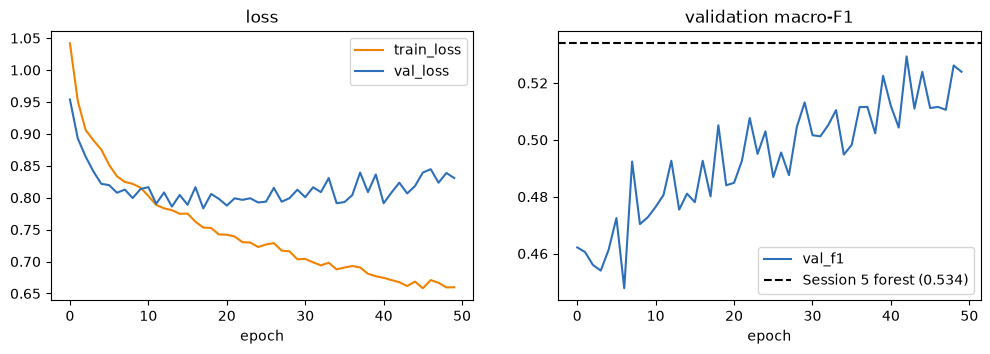

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
hist[["train_loss", "val_loss"]].plot(ax=axes[0], color=["#F08200", "#2E6FBA"], title="loss")
hist["val_f1"].plot(ax=axes[1], color="#2E6FBA", title="validation macro-F1")
axes[1].axhline(0.534, color="k", ls="--", label="Session 5 forest (0.534)")
axes[1].legend();

In [35]:
model.eval()
with torch.no_grad():
    val_pred = model(Xva).argmax(1)
mlp_val_f1 = f1_score(y_val, val_pred, average="macro")
print(f"MLP val macro-F1 = {mlp_val_f1:.3f}   (Session 5: majority 0.272, logreg 0.437, kNN 0.474, forest 0.534)")   # 0.493

MLP val macro-F1 = 0.524   (Session 5: majority 0.272, logreg 0.437, kNN 0.474, forest 0.534)


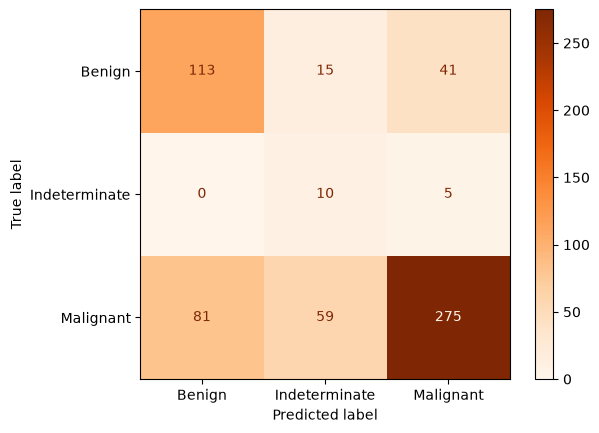

In [36]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=CLASSES, cmap="Oranges");

### 9. Overfitting on purpose — and three cures

75267


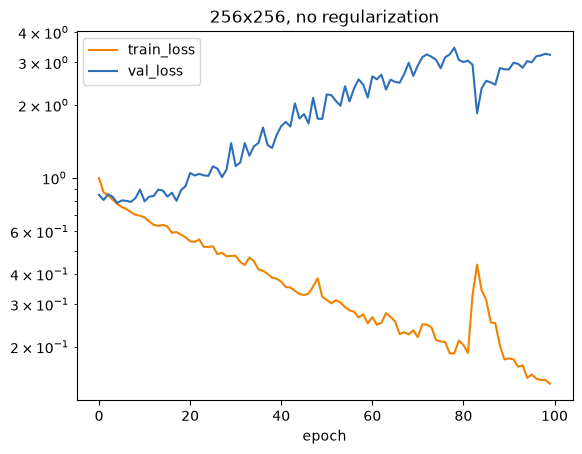

In [37]:
big = make_mlp(hidden=(256, 256))
print(sum(p.numel() for p in big.parameters()))           # 75267 weights
hist_big = fit(big, epochs=100)
hist_big[["train_loss", "val_loss"]].plot(color=["#F08200", "#2E6FBA"], logy=True,
                                          title="256x256, no regularization");

{'train_loss': 0.141, 'val_loss': 3.227, 'val_f1': 0.491}
{'train_loss': 0.425, 'val_loss': 1.547, 'val_f1': 0.539}


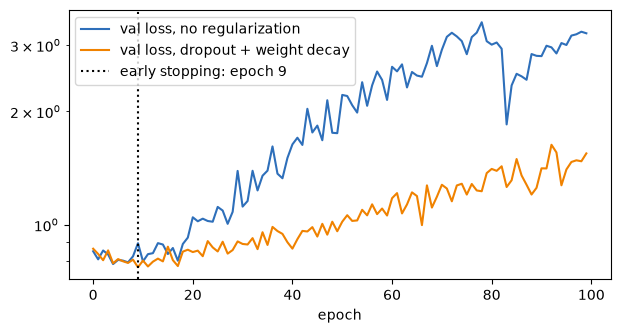

In [38]:
reg = make_mlp(hidden=(256, 256), dropout=0.3)
hist_reg = fit(reg, epochs=100, weight_decay=1e-4)

fig, ax = plt.subplots(figsize=(7, 3.5))
hist_big["val_loss"].plot(ax=ax, label="val loss, no regularization", color="#2E6FBA", logy=True)
hist_reg["val_loss"].plot(ax=ax, label="val loss, dropout + weight decay", color="#F08200")
best_epoch = hist_reg["val_loss"].idxmin()
ax.axvline(best_epoch, color="k", ls=":", label=f"early stopping: epoch {best_epoch}")
ax.legend();
print(hist_big.iloc[-1].round(3).to_dict())     # train 0.144, val loss 4.355, val F1 0.525
print(hist_reg.iloc[-1].round(3).to_dict())     # train 0.402, val loss 2.504, val F1 0.546

### 10. The test set — once — and the scoreboard

In [39]:
with torch.no_grad():
    test_pred = model(Xte).argmax(1)
test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")
print(f"TEST accuracy = {test_acc:.3f}   TEST macro-F1 = {test_f1:.3f}")     # 0.617   0.472

baseline = json.loads((ROOT / "session_05_classical_ml" / "_output" / "baseline_scores.json").read_text())
scoreboard = pd.DataFrame({
    "Session 5 - random forest (33 features)": [baseline["val_macro_f1"], baseline["test_macro_f1"]],
    "Session 6 - MLP 33-64-3 (33 features)": [round(mlp_val_f1, 3), round(test_f1, 3)],
}, index=["val macro-F1", "test macro-F1"]).T
scoreboard

TEST accuracy = 0.656   TEST macro-F1 = 0.491


FileNotFoundError: [Errno 2] No such file or directory: '/Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification/session_05_classical_ml/_output/baseline_scores.json'

In [ ]:
out_dir = ROOT / "session_06_neural_networks" / "_output"
out_dir.mkdir(exist_ok=True)
scores = {"model": "MLP 33-64-3 on Session 5's 33 handcrafted features",
          "val_macro_f1": round(float(mlp_val_f1), 3),
          "test_accuracy": round(float(test_acc), 3),
          "test_macro_f1": round(float(test_f1), 3)}
(out_dir / "mlp_scores.json").write_text(json.dumps(scores, indent=2))
scores

{'model': "MLP 33-64-3 on Session 5's 33 handcrafted features",
 'val_macro_f1': 0.493,
 'test_accuracy': 0.617,
 'test_macro_f1': 0.472}

MLP  TEST accuracy = 0.656   TEST macro-F1 = 0.491
RF   TEST accuracy = 0.752   TEST macro-F1 = 0.531

               precision    recall  f1-score   support

       Benign       0.61      0.62      0.61       297
Indeterminate       0.06      0.42      0.11        24
    Malignant       0.85      0.68      0.75       727

     accuracy                           0.66      1048
    macro avg       0.51      0.57      0.49      1048
 weighted avg       0.76      0.66      0.70      1048



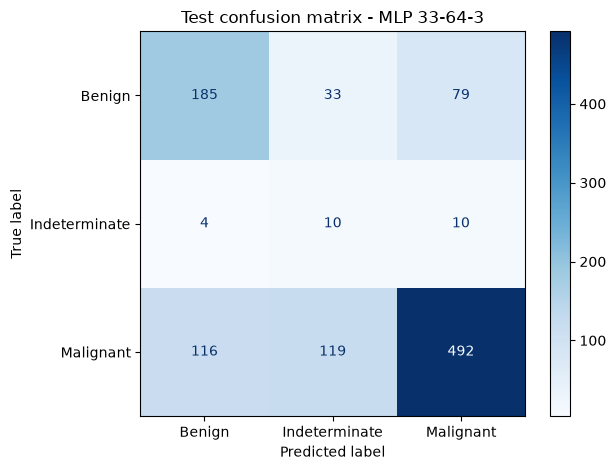

In [40]:
import json
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

# ---------- 1. MLP on the test set (opened once) ----------
model.eval()
with torch.no_grad():
    test_pred = model(Xte).argmax(1)
test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")
print(f"MLP  TEST accuracy = {test_acc:.3f}   TEST macro-F1 = {test_f1:.3f}")

# ---------- 2. Session 5 baseline: random forest, same 33 features, same split ----------
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2,
                            n_jobs=-1, random_state=0).fit(X_train, y_train.numpy())
rf_val_f1 = f1_score(y_val.numpy(), rf.predict(X_val), average="macro")
rf_test_pred = rf.predict(X_test)
rf_test_f1 = f1_score(y_test.numpy(), rf_test_pred, average="macro")
rf_test_acc = accuracy_score(y_test.numpy(), rf_test_pred)
print(f"RF   TEST accuracy = {rf_test_acc:.3f}   TEST macro-F1 = {rf_test_f1:.3f}")

# ---------- 3. Scoreboard ----------
mlp_recall = recall_score(y_test, test_pred, labels=[0, 1, 2], average=None, zero_division=0)
rf_recall = recall_score(y_test, rf_test_pred, labels=[0, 1, 2], average=None, zero_division=0)

scoreboard = pd.DataFrame({
    "Session 5 - random forest (33 features)": [rf_val_f1, rf_test_f1, rf_test_acc, *rf_recall],
    "Session 6 - MLP 33-64-3 (33 features)":   [mlp_val_f1, test_f1, test_acc, *mlp_recall],
}, index=["val macro-F1", "test macro-F1", "test accuracy",
          f"recall {CLASSES[0]}", f"recall {CLASSES[1]}", f"recall {CLASSES[2]}"]).T.round(3)

# ---------- 4. Save ----------
out_dir = ROOT / "outputs";  out_dir.mkdir(exist_ok=True)
fig_dir = ROOT / "figures";  fig_dir.mkdir(exist_ok=True)

scoreboard.to_csv(out_dir / "session6_scoreboard.csv")
scores = {"model": "MLP 33-64-3 on Session 5's 33 handcrafted features",
          "val_macro_f1": round(float(mlp_val_f1), 3),
          "test_accuracy": round(float(test_acc), 3),
          "test_macro_f1": round(float(test_f1), 3),
          "forest_val_macro_f1": round(float(rf_val_f1), 3),
          "forest_test_macro_f1": round(float(rf_test_f1), 3)}
(out_dir / "mlp_scores.json").write_text(json.dumps(scores, indent=2))

print()
print(classification_report(y_test, test_pred, target_names=CLASSES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=CLASSES, cmap="Blues")
plt.title("Test confusion matrix - MLP 33-64-3")
plt.tight_layout()
plt.savefig(fig_dir / "session6_confusion_matrix_test.png", dpi=150)
plt.show()

### 11. Mini challenge — tune it

Change **one thing at a time**, train, and note the final **validation** macro-F1:

1. learning rate: `lr=0.1`, then `lr=1e-5`
2. width: `hidden=(4,)`, then `hidden=(256,)`
3. depth: `hidden=(64, 64)`

Number to beat: Session 5's random forest, **0.534**. The test set stays closed.

In [41]:
needed = ["torch", "nn", "pd", "np", "f1_score", "DataLoader", "TensorDataset",
          "Xtr", "Xva", "y_train", "y_val", "class_weights", "make_mlp", "fit"]
for n in needed:
    print(f"{n:15}", "OK" if n in globals() else "MISSING")

torch           OK
nn              OK
pd              OK
np              OK
f1_score        OK
DataLoader      OK
TensorDataset   OK
Xtr             OK
Xva             OK
y_train         OK
y_val           OK
class_weights   OK
make_mlp        OK
fit             OK


In [46]:
experiments = {
    "baseline (64, lr=1e-3)":  dict(hidden=(64,),    lr=1e-3),
    "lr = 0.1":                dict(hidden=(64,),    lr=0.1),
    "lr = 1e-5":               dict(hidden=(64,),    lr=1e-5),
    "width = 4":               dict(hidden=(4,),     lr=1e-3),
    "width = 256":             dict(hidden=(256,),   lr=1e-3),
    "depth = (64, 64)":        dict(hidden=(64, 64), lr=1e-3),
}

results, histories = [], {}
for name, cfg in experiments.items():
    model_i = make_mlp(hidden=cfg["hidden"])      # same seed -> same starting conditions
    hist_i = fit(model_i, epochs=50, lr=cfg["lr"])
    histories[name] = hist_i
    results.append({"experiment": name,
                    "final val F1": hist_i["val_f1"].iloc[-1],
                    "best val F1": hist_i["val_f1"].max(),
                    "final val loss": hist_i["val_loss"].iloc[-1]})

challenge = pd.DataFrame(results).set_index("experiment").round(3)
challenge["beats forest (0.534)?"] = challenge["final val F1"] > 0.534       # as in the instructions
challenge["beats my forest (0.547)?"] = challenge["final val F1"] > rf_val_f1 
challenge

,final val F1,best val F1,final val loss,beats forest (0.534)?,beats my forest (0.547)?
experiment,,,,,
"baseline (64, lr=1e-3)",0.524,0.529,0.831,False,False
lr = 0.1,0.439,0.525,1.191,False,False
lr = 1e-5,0.406,0.406,1.019,False,False
width = 4,0.469,0.470,0.844,False,False
width = 256,0.512,0.554,0.920,False,False
"depth = (64, 64)",0.526,0.545,0.970,False,False


In [44]:
seed_rows = []
for name, cfg in experiments.items():
    f1s = []
    for s in (0, 1, 2):
        m = make_mlp(hidden=cfg["hidden"], seed=s)
        f1s.append(fit(m, epochs=50, lr=cfg["lr"])["val_f1"].iloc[-1])
    seed_rows.append({"experiment": name,
                      "mean final val F1": np.mean(f1s),
                      "std": np.std(f1s)})

seed_table = pd.DataFrame(seed_rows).set_index("experiment").round(3)
seed_table.to_csv(ROOT / "outputs" / "session6_mini_challenge_3seeds.csv")
seed_table

,mean final val F1,std
experiment,,
"baseline (64, lr=1e-3)",0.513,0.010
lr = 0.1,0.423,0.039
lr = 1e-5,0.425,0.032
width = 4,0.449,0.014
width = 256,0.518,0.005
"depth = (64, 64)",0.514,0.019


Forest val macro-F1 (number to beat) = 0.547


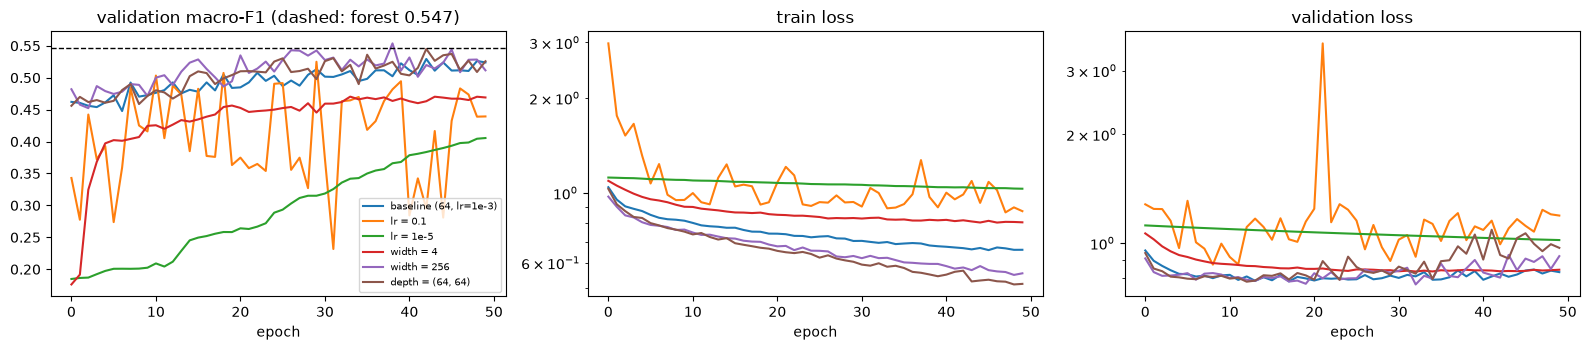

,parameters,final train loss,final val loss,final val F1,best val F1,best epoch,beats forest (0.547)?
experiment,,,,,,,
"baseline (64, lr=1e-3)",2371,0.660,0.831,0.524,0.529,42,False
lr = 0.1,2371,0.875,1.191,0.439,0.525,29,False
lr = 1e-5,2371,1.031,1.019,0.406,0.406,49,False
width = 4,151,0.806,0.844,0.469,0.470,33,False
width = 256,9475,0.556,0.920,0.512,0.554,38,False
"depth = (64, 64)",6531,0.514,0.970,0.526,0.545,42,False


In [45]:
from sklearn.ensemble import RandomForestClassifier

# number to beat: forest on YOUR split, same 33 features
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2,
                            n_jobs=-1, random_state=0).fit(X_train, y_train.numpy())
rf_val_f1 = f1_score(y_val.numpy(), rf.predict(X_val), average="macro")
print(f"Forest val macro-F1 (number to beat) = {rf_val_f1:.3f}")

results, histories = [], {}
for name, cfg in experiments.items():
    model_i = make_mlp(hidden=cfg["hidden"])               # same seed -> same starting conditions
    hist_i = fit(model_i, epochs=50, lr=cfg["lr"])
    histories[name] = hist_i
    results.append({"experiment": name,
                    "parameters": sum(p.numel() for p in model_i.parameters()),
                    "final train loss": hist_i["train_loss"].iloc[-1],
                    "final val loss": hist_i["val_loss"].iloc[-1],
                    "final val F1": hist_i["val_f1"].iloc[-1],
                    "best val F1": hist_i["val_f1"].max(),
                    "best epoch": hist_i["val_f1"].idxmax()})

challenge = pd.DataFrame(results).set_index("experiment").round(3)
challenge[f"beats forest ({rf_val_f1:.3f})?"] = challenge["final val F1"] > rf_val_f1
(ROOT / "outputs").mkdir(exist_ok=True)
challenge.to_csv(ROOT / "outputs" / "session6_mini_challenge.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for name, h in histories.items():
    axes[0].plot(h["val_f1"], label=name)
    axes[1].plot(h["train_loss"], label=name)
    axes[2].plot(h["val_loss"], label=name)
axes[0].axhline(rf_val_f1, color="k", ls="--", lw=1)
axes[0].set_title(f"validation macro-F1 (dashed: forest {rf_val_f1:.3f})")
axes[1].set_title("train loss"); axes[2].set_title("validation loss")
axes[1].set_yscale("log"); axes[2].set_yscale("log")
axes[0].legend(fontsize=7)
for a in axes:
    a.set_xlabel("epoch")
plt.tight_layout()
(ROOT / "figures").mkdir(exist_ok=True)
plt.savefig(ROOT / "figures" / "session6_mini_challenge.png", dpi=150)
plt.show()

challenge

### Mini-challenge results (validation only, test set not used)

Number to beat: Session 5's random forest, **0.534** (course reference). On my own split the same forest scores 0.547.
Setup: MLP on the 33 handcrafted features, 50 epochs, Adam, class-weighted loss, same initial weights for every run. One hyperparameter is changed at a time from the baseline 33-64-3 (lr = 1e-3).

| Experiment | Final val F1 (single run) | Final val F1 (mean ± std, 3 seeds) | Beats 0.534? | What the curves show |
|---|---|---|---|---|
| baseline 33-64-3, lr = 1e-3 | 0.524 | 0.513 ± 0.010 | No | Reference run; train loss 0.66, validation loss 0.83. |
| lr = 0.1 | 0.439 | 0.423 ± 0.039 | No | Too large: F1 and loss oscillate and the validation loss spikes (around epoch 20). Unstable. |
| lr = 1e-5 | 0.406 | 0.425 ± 0.032 | No | Too small: the loss barely moves (train 1.03) and F1 is still rising at epoch 50, so it is under-trained. |
| width = 4 | 0.469 | 0.449 ± 0.014 | No | Too little capacity: train loss stays high (0.81) and F1 plateaus at about 0.47. |
| width = 256 | 0.512 | 0.518 ± 0.005 | No | Train loss falls faster (0.56), but validation loss is higher than the baseline (0.92 vs 0.83): starts to overfit. |
| depth = (64, 64) | 0.526 | 0.514 ± 0.019 | No | Lowest train loss (0.51) but validation loss 0.97: more overfitting, no real gain. |

**Conclusions**
- The learning rate matters most: both extremes (0.1 and 1e-5) lower the validation F1 by about 0.09 compared with the baseline, much more than the seed-to-seed noise (std 0.01-0.04).
- Width 256 and depth (64, 64) are tied with the baseline within seed noise (0.513-0.518). More capacity lowers the training loss but not the validation loss, so the larger networks mainly overfit.
- No configuration beats the reference of 0.534 on the final validation macro-F1; the closest are depth (64, 64) with 0.526 and the baseline with 0.524 in the single runs. None beats my own forest (0.547) either.
- The "best val F1" column (up to 0.554 for width = 256) is a maximum over epochs chosen on the validation set, so it is optimistic and is not used for this comparison. It only suggests that early stopping could help the larger networks.
- Interpretation: with only 33 handcrafted features and about 3,600 training lesions, the information in the input seems to limit the model more than its architecture does. This motivates Session 7, where convolutions work directly on the pixels.
- Possible next steps: early stopping on the validation loss, dropout or weight decay for the larger networks, and training lr = 1e-5 for more epochs.

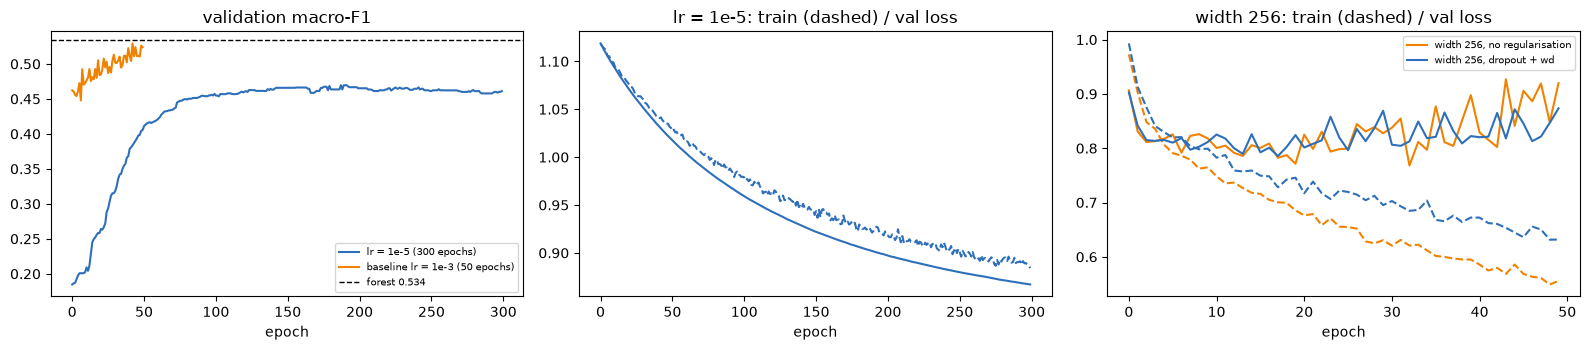

,epochs,train loss,val loss,val-train gap,final val F1,best val F1
run,,,,,,
"lr = 1e-5, 50 epochs (challenge)",50,1.031,1.019,-0.011,0.406,0.406
"lr = 1e-5, 300 epochs",300,0.884,0.867,-0.017,0.461,0.470
"baseline 64, lr = 1e-3, 50 epochs",50,0.660,0.831,0.171,0.524,0.529
"width = 256, no regularisation",50,0.556,0.920,0.364,0.512,0.554
"width = 256, dropout 0.3 + wd 1e-4",50,0.632,0.873,0.242,0.514,0.541


In [47]:
# ---- Extra 1: is lr = 1e-5 only slow, or broken?  (same model, 300 epochs instead of 50) ----
m_slow = make_mlp(hidden=(64,))
h_slow = fit(m_slow, epochs=300, lr=1e-5)

# ---- Extra 2: does regularisation fix the width-256 overfitting?  (same 50 epochs) ----
m_reg = make_mlp(hidden=(256,), dropout=0.3)
h_reg = fit(m_reg, epochs=50, lr=1e-3, weight_decay=1e-4)
h_256 = histories["width = 256"]                 # width 256 without regularisation (from the challenge)
h_base = histories["baseline (64, lr=1e-3)"]

# ---- table ----
def row(name, h, epoch=None):
    r = h.iloc[-1] if epoch is None else h.iloc[epoch]
    return {"run": name, "epochs": len(h), "train loss": r["train_loss"], "val loss": r["val_loss"],
            "val-train gap": r["val_loss"] - r["train_loss"], "final val F1": r["val_f1"],
            "best val F1": h["val_f1"].max()}

extras = pd.DataFrame([
    row("lr = 1e-5, 50 epochs (challenge)", histories["lr = 1e-5"]),
    row("lr = 1e-5, 300 epochs", h_slow),
    row("baseline 64, lr = 1e-3, 50 epochs", h_base),
    row("width = 256, no regularisation", h_256),
    row("width = 256, dropout 0.3 + wd 1e-4", h_reg),
]).set_index("run").round(3)
extras.to_csv(ROOT / "outputs" / "session6_mini_challenge_extras.csv")

# ---- curves ----
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].plot(h_slow["val_f1"], color="#2E6FBA", label="lr = 1e-5 (300 epochs)")
axes[0].plot(h_base["val_f1"], color="#F08200", label="baseline lr = 1e-3 (50 epochs)")
axes[0].axhline(0.534, color="k", ls="--", lw=1, label="forest 0.534")
axes[0].set_title("validation macro-F1"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=7)
axes[1].plot(h_slow["train_loss"], "--", color="#2E6FBA"); axes[1].plot(h_slow["val_loss"], color="#2E6FBA")
axes[1].set_title("lr = 1e-5: train (dashed) / val loss"); axes[1].set_xlabel("epoch")
for h, col, lab in [(h_256, "#F08200", "width 256, no regularisation"),
                    (h_reg, "#2E6FBA", "width 256, dropout + wd")]:
    axes[2].plot(h["train_loss"], "--", color=col)
    axes[2].plot(h["val_loss"], color=col, label=lab)
axes[2].set_title("width 256: train (dashed) / val loss"); axes[2].set_xlabel("epoch"); axes[2].legend(fontsize=7)
plt.tight_layout()
plt.savefig(ROOT / "figures" / "session6_mini_challenge_extras.png", dpi=150)
plt.show()

extras

### Homework · Before Session 7

1. Add your MLP's validation and test macro-F1 to the scoreboard, next to Session 5's forest.
2. Read the docs of nn.Conv2d: which arguments are Session 4's kernel size, stride and padding?
3. Train the MLP on raw pixels (32×32×3 = 3,072 numbers). Better or worse than 33 features? Why?

In [2]:
import json, random, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from scipy import ndimage
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

random.seed(0); np.random.seed(0); torch.manual_seed(0)


def find_project_root():
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "milk10k" / "metadata.csv").is_file():
            return p
    raise FileNotFoundError(f"data/milk10k/metadata.csv not found above {start}")


ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "milk10k"
IMG_DIR = DATA_DIR / "images"
for d in ("outputs", "figures", "reports"):
    (ROOT / d).mkdir(exist_ok=True)
image_index = {p.stem: p for p in IMG_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
print("project root:", ROOT, "| images indexed:", len(image_index))

# ---- data: target is diagnosis_1 from metadata.csv, one dermoscopic image per lesion ----
df = pd.read_csv(DATA_DIR / "metadata.csv").dropna(subset=["diagnosis_1"])
df = df[df["image_type"].astype(str).str.contains("dermoscopic", case=False)].reset_index(drop=True)
assert df["lesion_id"].is_unique
assert all(i in image_index for i in df["isic_id"]), "some images are missing on disk"
CLASSES = sorted(df["diagnosis_1"].unique())            # ['Benign', 'Indeterminate', 'Malignant']
assert len(CLASSES) == 3
to_int = {c: i for i, c in enumerate(CLASSES)}
print(df["diagnosis_1"].value_counts().to_string())


# ---- leak-free split: grouped by lesion_id, stratified by diagnosis ----
def make_splits(df, seed=0):
    y = df["diagnosis_1"].astype("category").cat.codes.to_numpy()
    groups = df["lesion_id"].to_numpy()
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    trval, te = next(outer.split(np.zeros(len(df)), y, groups))
    inner = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    tr_rel, va_rel = next(inner.split(np.zeros(len(trval)), y[trval], groups[trval]))
    tr, va = trval[tr_rel], trval[va_rel]
    for a, b in [(tr, va), (tr, te), (va, te)]:
        assert set(groups[a]).isdisjoint(groups[b]), "lesion leakage between splits"
    return [df.iloc[i].reset_index(drop=True) for i in (tr, va, te)]


train_df, val_df, test_df = make_splits(df, seed=0)
print("split sizes:", len(train_df), len(val_df), len(test_df))
all_ids = np.concatenate([d["isic_id"].to_numpy() for d in (train_df, val_df, test_df)])


# ---- Session 5: 33 handcrafted features ----
def color_stats(rgb):
    return np.concatenate([rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1))])

def color_histogram(rgb, bins=8):
    n_pixels = rgb.shape[0] * rgb.shape[1]
    return np.concatenate([np.histogram(rgb[:, :, c], bins=bins, range=(0, 256))[0] / n_pixels
                           for c in range(3)])

def texture_features(rgb):
    gray = rgb.mean(axis=2)
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray ** 2, size=9)
    return np.array([np.hypot(gx, gy).mean(), (local_sq_mean - local_mean ** 2).mean(),
                     ndimage.laplace(gray).var()])

def extract_features(isic_id):
    img = Image.open(image_index[isic_id]); img.draft("RGB", (400, 300))
    rgb = np.array(img.convert("RGB").resize((200, 150)), dtype=float)
    return np.concatenate([color_stats(rgb), color_histogram(rgb), texture_features(rgb)])

def load_pixels(isic_id):                               # 32x32x3 = 3072 numbers
    img = Image.open(image_index[isic_id]); img.draft("RGB", (128, 128))
    img = img.convert("RGB").resize((32, 32), Image.Resampling.BOX)
    return np.asarray(img, dtype=np.uint8).reshape(-1)


def build_cache(path, build, prefix):
    if path.exists():
        c = np.load(path, allow_pickle=True)
        if "ids" in c.files and len(c["ids"]) == len(all_ids) and (c["ids"] == all_ids).all():
            print("loaded cache:", path.name)
            return c
    t0 = time.perf_counter()
    data = {f"{prefix}_{n}": np.stack([build(i) for i in d["isic_id"]])
            for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    data["ids"] = all_ids
    np.savez(path, **data)
    print(f"built {path.name} in {time.perf_counter() - t0:.0f} s")
    return np.load(path, allow_pickle=True)


fc = build_cache(ROOT / "outputs" / "features_33.npz", extract_features, "X")
X_train, X_val, X_test = fc["X_train"], fc["X_val"], fc["X_test"]
pc = build_cache(ROOT / "outputs" / "pixels_32.npz", load_pixels, "P")
P_train, P_val, P_test = (pc[f"P_{n}"].astype(np.float32) / 255.0 for n in ("train", "val", "test"))
print("features:", X_train.shape, X_val.shape, X_test.shape, "| pixels:", P_train.shape)
assert X_train.shape[1] == 33 and P_train.shape[1] == 3072

project root: /Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification | images indexed: 10480
diagnosis_1
Malignant        3634
Benign           1483
Indeterminate     123
split sizes: 3593 599 1048
loaded cache: features_33.npz
loaded cache: pixels_32.npz
features: (3593, 33) (599, 33) (1048, 33) | pixels: (3593, 3072)


In [3]:
y_train, y_val, y_test = (torch.tensor(d["diagnosis_1"].map(to_int).to_numpy()) for d in (train_df, val_df, test_df))
class_weights = len(y_train) / (3 * torch.bincount(y_train).float())
print("class counts (train):", torch.bincount(y_train).tolist(), "-> weights", class_weights.numpy().round(2))


def to_tensors(A_tr, A_va, A_te):
    sc = StandardScaler().fit(A_tr)                                       # train only
    return tuple(torch.tensor(sc.transform(A), dtype=torch.float32) for A in (A_tr, A_va, A_te))


Xtr, Xva, Xte = to_tensors(X_train, X_val, X_test)                         # 33 features
Ptr, Pva, Pte = to_tensors(P_train, P_val, P_test)                         # raw pixels


def make_mlp(hidden=(64,), dropout=0.0, seed=0, d_in=33, n_out=3):
    torch.manual_seed(seed)
    layers = []
    for h in hidden:
        layers += [nn.Linear(d_in, h), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        d_in = h
    layers.append(nn.Linear(d_in, n_out))
    return nn.Sequential(*layers)


def fit(model, epochs=50, lr=1e-3, weight_decay=0.0, batch_size=64, data=None, seed=0):
    X_tr, y_tr, X_va, y_va = data if data is not None else (Xtr, y_train, Xva, y_val)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True, generator=g)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_logits = model(X_va)
            history.append({"epoch": epoch, "train_loss": total / len(X_tr),
                            "val_loss": loss_fn(val_logits, y_va).item(),
                            "val_f1": f1_score(y_va.numpy(), val_logits.argmax(1).numpy(),
                                               average="macro", zero_division=0)})
    return pd.DataFrame(history).set_index("epoch")


# ---- baseline: MLP 33-64-3 on the 33 features (the class model) ----
model = make_mlp()
hist = fit(model)
mlp_val_f1 = float(hist["val_f1"].iloc[-1])
print(f"MLP 33-64-3: {sum(p.numel() for p in model.parameters())} parameters, val macro-F1 = {mlp_val_f1:.3f}")

# ---- homework 3: the same MLP on raw pixels (3072 inputs) ----
pix_runs = {"pixels 3072-64-3": dict(dropout=0.0, wd=0.0),
            "pixels 3072-64-3 + dropout 0.3, wd 1e-4": dict(dropout=0.3, wd=1e-4)}
pix_models, pix_hist, pix_rows = {}, {}, []
for name, cfg in pix_runs.items():
    m = make_mlp(hidden=(64,), dropout=cfg["dropout"], d_in=3072)
    h = fit(m, epochs=50, lr=1e-3, weight_decay=cfg["wd"], data=(Ptr, y_train, Pva, y_val))
    pix_models[name], pix_hist[name] = m, h
    pix_rows.append({"model": name, "parameters": sum(p.numel() for p in m.parameters()),
                     "final train loss": h["train_loss"].iloc[-1], "final val loss": h["val_loss"].iloc[-1],
                     "final val F1": h["val_f1"].iloc[-1], "best val F1": h["val_f1"].max()})

feat_row = {"model": "33 features 33-64-3 (class baseline)",
            "parameters": sum(p.numel() for p in model.parameters()),
            "final train loss": hist["train_loss"].iloc[-1], "final val loss": hist["val_loss"].iloc[-1],
            "final val F1": hist["val_f1"].iloc[-1], "best val F1": hist["val_f1"].max()}
pix_table = pd.DataFrame([feat_row] + pix_rows).set_index("model").round(3)
pix_table.to_csv(ROOT / "outputs" / "session6_pixels_vs_features.csv")

f_feat, f_pix = feat_row["final val F1"], pix_rows[0]["final val F1"]
gap_feat = feat_row["final val loss"] - feat_row["final train loss"]
gap_pix = pix_rows[0]["final val loss"] - pix_rows[0]["final train loss"]
print(f"Raw pixels are {'BETTER' if f_pix > f_feat else 'WORSE'} than the 33 features: "
      f"val macro-F1 {f_pix:.3f} vs {f_feat:.3f}")
print(f"Val-train loss gap: pixels {gap_pix:.2f} vs features {gap_feat:.2f}")
pix_table

class counts (train): [1017, 84, 2492] -> weights [ 1.18 14.26  0.48]
MLP 33-64-3: 2371 parameters, val macro-F1 = 0.532
Raw pixels are WORSE than the 33 features: val macro-F1 0.454 vs 0.532
Val-train loss gap: pixels 2.38 vs features 0.19


,parameters,final train loss,final val loss,final val F1,best val F1
model,,,,,
33 features 33-64-3 (class baseline),2371,0.653,0.843,0.532,0.534
pixels 3072-64-3,196867,0.207,2.591,0.454,0.546
"pixels 3072-64-3 + dropout 0.3, wd 1e-4",196867,0.512,1.592,0.518,0.549


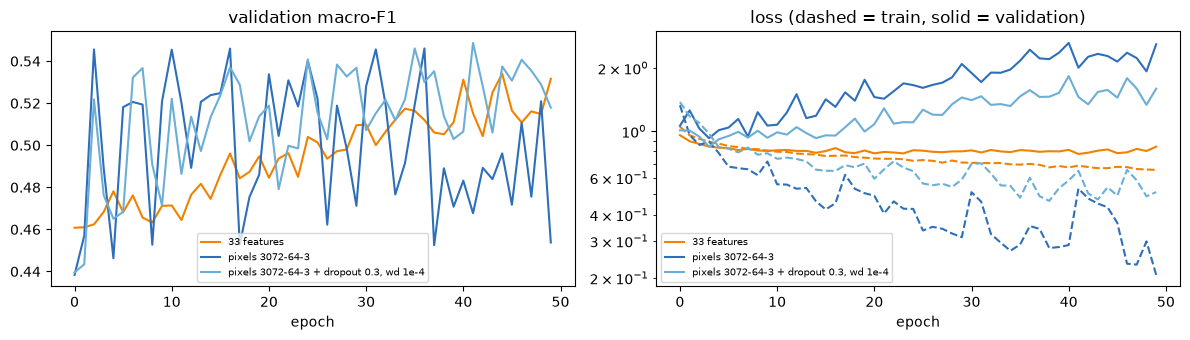

,kernel_size,stride,padding,output shape,parameters
0,3,1,0,"(1, 8, 30, 30)",224
1,3,1,1,"(1, 8, 32, 32)",224
2,3,2,1,"(1, 8, 16, 16)",224
3,5,1,2,"(1, 8, 32, 32)",608


,val macro-F1,test macro-F1,test accuracy,recall Benign,recall Indeterminate,recall Malignant
Session 5 - random forest (33 features),0.547,0.531,0.752,0.566,0.125,0.849
Session 6 - MLP 33-64-3 (33 features),0.532,0.508,0.680,0.606,0.458,0.718
"Session 6 - MLP on raw pixels (pixels 3072-64-3 + dropout 0.3, wd 1e-4)",0.518,0.484,0.687,0.697,0.125,0.702


In [4]:
# ---------- Homework 1: scoreboard (the test set is opened here, once) ----------
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2,
                            n_jobs=-1, random_state=0).fit(X_train, y_train.numpy())
best_pix = max(pix_rows, key=lambda r: r["final val F1"])["model"]      # chosen on validation
mlp_pix = pix_models[best_pix]
yv, yt = y_val.numpy(), y_test.numpy()


def score(pred_val, pred_test):
    rec = recall_score(yt, pred_test, labels=[0, 1, 2], average=None, zero_division=0)
    return {"val macro-F1": f1_score(yv, pred_val, average="macro", zero_division=0),
            "test macro-F1": f1_score(yt, pred_test, average="macro", zero_division=0),
            "test accuracy": accuracy_score(yt, pred_test),
            **{f"recall {c}": r for c, r in zip(CLASSES, rec)}}


def mlp_pred(m, Xv, Xt):
    m.eval()
    with torch.no_grad():
        return m(Xv).argmax(1).numpy(), m(Xt).argmax(1).numpy()


scoreboard = pd.DataFrame({
    "Session 5 - random forest (33 features)": score(rf.predict(X_val), rf.predict(X_test)),
    "Session 6 - MLP 33-64-3 (33 features)": score(*mlp_pred(model, Xva, Xte)),
    f"Session 6 - MLP on raw pixels ({best_pix})": score(*mlp_pred(mlp_pix, Pva, Pte)),
}).T.round(3)
scoreboard.to_csv(ROOT / "outputs" / "session6_scoreboard.csv")
(ROOT / "outputs" / "mlp_scores.json").write_text(json.dumps(
    {"val_macro_f1": float(scoreboard.iloc[1]["val macro-F1"]),
     "test_macro_f1": float(scoreboard.iloc[1]["test macro-F1"]),
     "test_accuracy": float(scoreboard.iloc[1]["test accuracy"])}, indent=2))

# ---------- Homework 3: curves ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(hist["val_f1"], color="#F08200", label="33 features")
axes[1].plot(hist["train_loss"], "--", color="#F08200"); axes[1].plot(hist["val_loss"], color="#F08200", label="33 features")
for (name, h), col in zip(pix_hist.items(), ["#2E6FBA", "#6BAED6"]):
    axes[0].plot(h["val_f1"], color=col, label=name)
    axes[1].plot(h["train_loss"], "--", color=col); axes[1].plot(h["val_loss"], color=col, label=name)
axes[0].set_title("validation macro-F1"); axes[1].set_title("loss (dashed = train, solid = validation)")
axes[1].set_yscale("log")
for a in axes:
    a.set_xlabel("epoch"); a.legend(fontsize=7)
plt.tight_layout()
plt.savefig(ROOT / "figures" / "session6_pixels_vs_features.png", dpi=150)
plt.show()

# ---------- Homework 2: nn.Conv2d (kernel_size, stride, padding) ----------
x = torch.randn(1, 3, 32, 32)
rows = []
for kw in [dict(kernel_size=3, stride=1, padding=0), dict(kernel_size=3, stride=1, padding=1),
           dict(kernel_size=3, stride=2, padding=1), dict(kernel_size=5, stride=1, padding=2)]:
    conv = nn.Conv2d(in_channels=3, out_channels=8, **kw)
    out = conv(x)
    assert out.shape[-1] == (32 + 2 * kw["padding"] - kw["kernel_size"]) // kw["stride"] + 1
    rows.append({**kw, "output shape": tuple(out.shape), "parameters": sum(p.numel() for p in conv.parameters())})
display(pd.DataFrame(rows))

scoreboard